## Text classification with RNN models

## Importing Libraries

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd
import gensim.downloader as api
import matplotlib.pyplot as plt
import numpy as np
import re
from keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

## Assert whether "PyTorch" can use an available GPU card

In [2]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print(device)

cpu


## Data Preprocessing

In [3]:
# Load IMDB dataset
max_vocab_size = 10000
max_length = 300

(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=max_vocab_size)

# Pad sequences to a fixed length
train_tokens = pad_sequences(train_data, maxlen=max_length, padding='post', truncating='post')
test_tokens = pad_sequences(test_data, maxlen=max_length, padding='post', truncating='post')

print(f'Number of training examples: {len(train_tokens)}')
print(f'Number of test examples: {len(test_tokens)}')

Number of training examples: 25000
Number of test examples: 25000


## Load Word2Vec embeddings

In [4]:
word2vec = api.load('word2vec-google-news-300')
embedding_dim = 300
average_embedding = np.mean(word2vec.vectors, axis=0)
embedding_matrix = np.zeros((max_vocab_size, embedding_dim))
embedding_matrix[0] = np.zeros(embedding_dim)  # PAD token embedding
embedding_matrix[1] = average_embedding  # UNK token embedding

# Map word indices from IMDB to Word2Vec
word_index = imdb.get_word_index()
reverse_word_index = {value + 3: key for key, value in word_index.items()}
reverse_word_index[0] = '<pad>'
reverse_word_index[1] = '<start>'
reverse_word_index[2] = '<unk>'
reverse_word_index[3] = '<unused>'

for i in range(4, max_vocab_size):
    word = reverse_word_index.get(i, '<unk>')
    if word in word2vec:
        embedding_matrix[i] = word2vec[word]
    else:
        embedding_matrix[i] = average_embedding

## Creating a Dataset

In [5]:
# Dataset class
class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.texts[idx]), torch.tensor(self.labels[idx])

train_dataset = TextDataset(train_tokens, train_labels)
test_dataset = TextDataset(test_tokens, test_labels)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

## Define the model

In [6]:
# Define RNN, GRU, and LSTM models with optional Global Max Pooling
class RNNModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, model_type='RNN', pretrained=True, freeze=False, use_pooling=False):
        super(RNNModel, self).__init__()
        self.use_pooling = use_pooling
        if pretrained:
            self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix, dtype=torch.float32), freeze=freeze)
        else:
            self.embedding = nn.Embedding(vocab_size, embed_dim)
        rnn_class = {'RNN': nn.RNN, 'GRU': nn.GRU, 'LSTM': nn.LSTM}[model_type]
        self.rnn = rnn_class(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        embedded = self.embedding(x)
        output, _ = self.rnn(embedded)
        if self.use_pooling:
            pooled = torch.max(output, dim=1)[0]
            return torch.sigmoid(self.fc(pooled))
        else:
            return torch.sigmoid(self.fc(output[:, -1, :]))

## Training and Evaluation scripts

In [7]:
# Training and Evaluation Functions with loss tracking

# Training function
def train_model(model, train_loader, test_loader, criterion, optimizer, epochs=5): #epochs=10
    model.train()
    train_losses, test_losses = [], []

    for epoch in range(epochs):
        train_loss = 0
        model.train()
        for texts, labels in train_loader:
            texts, labels = texts.to(device), labels.float().to(device)
            optimizer.zero_grad()
            outputs = model(texts).squeeze()
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Calculate average loss for the epoch
        avg_train_loss = train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # Evaluate model on test data
        test_loss = 0
        model.eval()
        with torch.no_grad():
            for texts, labels in test_loader:
                texts, labels = texts.to(device), labels.float().to(device)
                outputs = model(texts).squeeze()
                loss = criterion(outputs, labels)
                test_loss += loss.item()

        avg_test_loss = test_loss / len(test_loader)
        test_losses.append(avg_test_loss)

        print(f'Epoch {epoch+1}/{epochs}, Train Loss: {avg_train_loss:.4f}, Test Loss: {avg_test_loss:.4f}')

    return train_losses, test_losses

# Evaluation function

def evaluate_model(model, test_loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for texts, labels in test_loader:
            texts = texts.to(device)
            preds = model(texts).squeeze() > 0.5
            y_true.extend(labels.tolist())
            y_pred.extend(preds.tolist())
    report = classification_report(y_true, y_pred, target_names=['Negative', 'Positive'], output_dict=True)
    return report

## Initialize models and compare...

Epoch 1/5, Train Loss: 0.3863, Test Loss: 0.2828
Epoch 2/5, Train Loss: 0.2065, Test Loss: 0.3293
Epoch 3/5, Train Loss: 0.1300, Test Loss: 0.2937
Epoch 4/5, Train Loss: 0.0817, Test Loss: 0.3713
Epoch 5/5, Train Loss: 0.0558, Test Loss: 0.4086


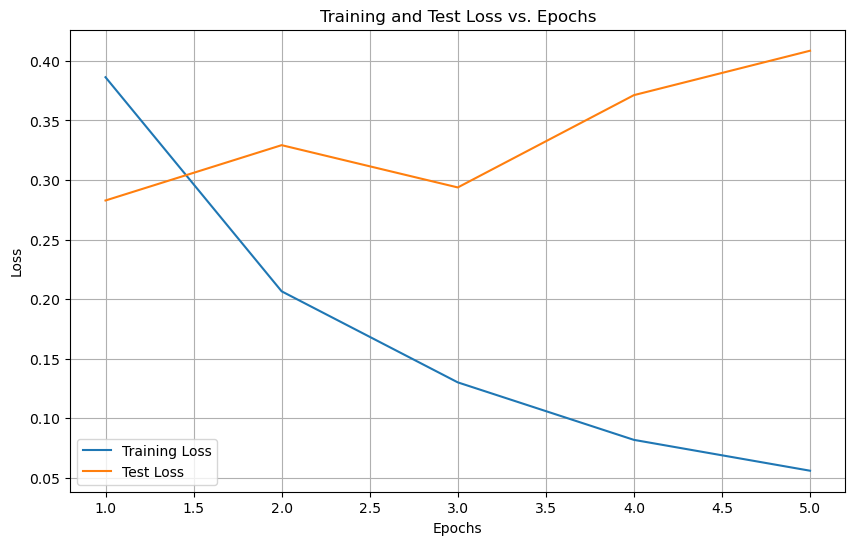

              precision   recall  f1-score      support
Negative       0.843099  0.90360  0.872302  12500.00000
Positive       0.896148  0.83184  0.862797  12500.00000
accuracy       0.867720  0.86772  0.867720      0.86772
macro avg      0.869623  0.86772  0.867549  25000.00000
weighted avg   0.869623  0.86772  0.867549  25000.00000


In [8]:
# Initialize model, criterion, optimizer
model = RNNModel(max_vocab_size, 300, 32, 1, 'LSTM', pretrained=True, use_pooling=True)
model.to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train the model and track losses
train_losses, test_losses = train_model(model, train_loader, test_loader, criterion, optimizer, epochs=5) #epochs=10

# Plot training and test losses
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss')
plt.plot(range(1, len(test_losses) + 1), test_losses, label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training and Test Loss vs. Epochs')
plt.legend()
plt.grid(True)
plt.show()

# Evaluate model performance
report = evaluate_model(model, test_loader)

# Display classification report as a table
report_df = pd.DataFrame(report).transpose()
print(report_df)

## Learning Curves: Precision, Recall, and F1


Training with 5000 examples (fraction: 0.2)
Epoch 1/5, Train Loss: 0.6258, Test Loss: 0.4873
Epoch 2/5, Train Loss: 0.4285, Test Loss: 0.4758
Epoch 3/5, Train Loss: 0.2742, Test Loss: 0.3653
Epoch 4/5, Train Loss: 0.2040, Test Loss: 0.3556
Epoch 5/5, Train Loss: 0.1056, Test Loss: 0.4120

Training with 10000 examples (fraction: 0.4)
Epoch 1/5, Train Loss: 0.5060, Test Loss: 0.3260
Epoch 2/5, Train Loss: 0.2555, Test Loss: 0.3302
Epoch 3/5, Train Loss: 0.1410, Test Loss: 0.3561
Epoch 4/5, Train Loss: 0.0807, Test Loss: 0.4148
Epoch 5/5, Train Loss: 0.0552, Test Loss: 0.4746

Training with 15000 examples (fraction: 0.6)
Epoch 1/5, Train Loss: 0.4573, Test Loss: 0.3187
Epoch 2/5, Train Loss: 0.2327, Test Loss: 0.2949
Epoch 3/5, Train Loss: 0.1359, Test Loss: 0.3777
Epoch 4/5, Train Loss: 0.0781, Test Loss: 0.3977
Epoch 5/5, Train Loss: 0.0504, Test Loss: 0.4288

Training with 20000 examples (fraction: 0.8)
Epoch 1/5, Train Loss: 0.4236, Test Loss: 0.2980
Epoch 2/5, Train Loss: 0.2169, Te

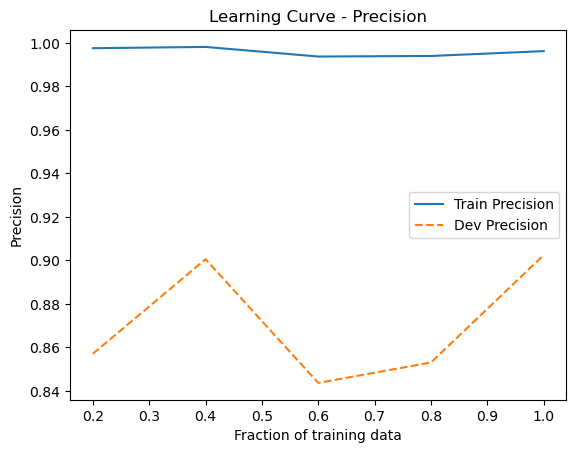

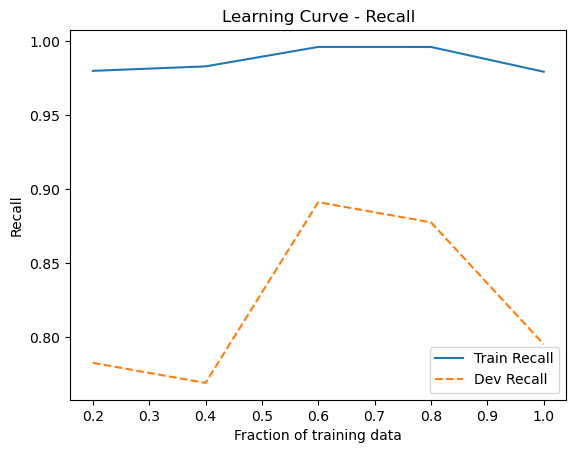

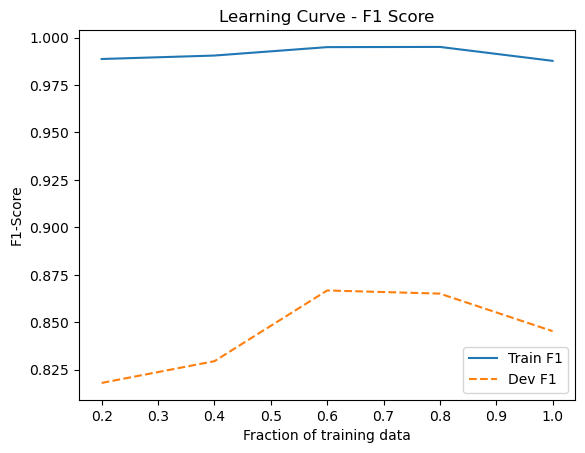

In [9]:
# Define fractions of the training set to use (20%, 40%, ..., 100%)
fractions = np.linspace(0.2, 1.0, 5)

# Lists to store metrics and training example counts
training_examples = []

train_precision, dev_precision = [], []
train_recall, dev_recall = [], []
train_f1, dev_f1 = [], []

# Loop through each fraction of the training data
for frac in fractions:
    # Calculate the number of examples to use for the current experiment
    n_examples = int(frac * len(train_dataset))
    training_examples.append(n_examples)

    # Select a subset of the training dataset
    subset_indices = list(range(n_examples))
    train_subset = Subset(train_dataset, subset_indices)
    train_subset_loader = DataLoader(train_subset, batch_size=32, shuffle=True)

    # Re-initialize the model, optimizer, and criterion for each experiment
    model_exp = RNNModel(max_vocab_size, 300, 32, 1, model_type='LSTM', pretrained=True, use_pooling=True)
    model_exp.to(device)
    criterion_exp = nn.BCELoss()
    optimizer_exp = optim.Adam(model_exp.parameters(), lr=0.001)

    print(f"\nTraining with {n_examples} examples (fraction: {frac:.1f})")
    
    # Train the model on the subset (e.g., for 5 epochs)
    train_model(model_exp, train_subset_loader, test_loader, criterion_exp, optimizer_exp, epochs=5)

    # Evaluate on the training subset
    train_report = evaluate_model(model_exp, train_subset_loader)
    # Evaluate on the development (test) data
    dev_report = evaluate_model(model_exp, test_loader)

    # Record the metrics for the "Positive" class
    train_precision.append(train_report['Positive']['precision'])
    dev_precision.append(dev_report['Positive']['precision'])
    
    train_recall.append(train_report['Positive']['recall'])
    dev_recall.append(dev_report['Positive']['recall'])

    train_f1.append(train_report['Positive']['f1-score'])
    dev_f1.append(dev_report['Positive']['f1-score'])

# Plotting learning curves for each metric

# Plot Precision
plt.figure()
plt.plot(fractions, train_precision, label="Train Precision")
plt.plot(fractions, dev_precision, label="Dev Precision", linestyle="--")
plt.xlabel("Fraction of training data")
plt.ylabel("Precision")
plt.title("Learning Curve - Precision")
plt.legend()
plt.show()

# Plot Recall
plt.figure()
plt.plot(fractions, train_recall, label="Train Recall")
plt.plot(fractions, dev_recall, label="Dev Recall", linestyle="--")
plt.xlabel("Fraction of training data")
plt.ylabel("Recall")
plt.title("Learning Curve - Recall")
plt.legend()
plt.show()

# Plot F1-Score
plt.figure()
plt.plot(fractions, train_f1, label="Train F1")
plt.plot(fractions, dev_f1, label="Dev F1", linestyle="--")
plt.xlabel("Fraction of training data")
plt.ylabel("F1-Score")
plt.title("Learning Curve - F1 Score")
plt.legend()
plt.show()